# NBA Player Analytics: Predicting Wins, Injuries, and Social Media Engagement

## Link to video
https://drive.google.com/file/d/12o1vdeMQpbp_SFpi4oWyzFS5KrswXYVP/view?usp=sharing

## Abstract

For our project we wanted to find which variables are most predictive of NBA player's wins, injuries, and social media engagement. It is important to know that we were not trying to prove causation, just predictability. We tried to find the most predictive variables by looking at correlation. We used three datasets to make regression plots and correlation matrices. 

We found that for player wins, high efficency, impact and minutes per game and indicative of high career wins. For injuries we were not able to find a significant predictor, only that players with less minutes per game are usually those who had injuries but this only reflects the idea that injured players do not play when recovering. Players with higher scoring output and impact usually have higher social media engagement.

## Authors

- John-Paul Nguyen: Writing - original draft, Project administration, Methodology
- Kheoni Basa: Conceptualization, Methodology, Data curation
- Gareth Arroyo: Background Research, Visualization
- Kimberly Sisouk: Writing - review and editing, Experimental investigation
- Ethan Baquiran: Background research, Software

## Research Question

Which NBA player's statistics found in regular season data can be used to predict their career game wins, the number of injuries they will have, and their popularity and engagement on Twitter over the 2016-2017 season?

## Background and Prior Work

Recent developments in sports analytics have demonstrated that player-level performance metrics can meaningfully explain team-level success in professional basketball. Instead of focusing on single game predictions, this study investigates which NBA statlines best predict a player's career success, which will be measured by the team's total team wins per season. This project will also be applying XGBoost for predictive accuracy, using it as a tool to measure feature importance which allows us to identify which measures contribute most and least to explaining variation in team wins. This approach mainly focuses on which parts of someone's career are mostly associated with their success.

Prior data science work has demonstrated similar approaches. A project published onto Towards Data Science <a name="cite_ref-1"></a>[<sup>1</sup>](#cite_note-1) used historical NBA player stats and machine learning regression models to predict the Most Valuable Player outcomes. The study represents how feature engineering and model techniques can be used to capture the patterns in each player's performance using data and can emphasize which stats were most important to coming to that conclusion. Although the project honed in on the predictions based on the award, it supports the idea that certain stats play a higher role in prediction than others.

Another data science project used XGBoost to predict a player’s points per game throughout the season. This project published by Arving Rangarajan on August 28, 2025 <a name="cite_ref-2"></a>[<sup>2</sup>](#cite_note-2), used many player stats including some from two seasons before and comparison from previous season to current season to predict with different levels of confidence the player’s performance in the season overall. Essentially the project uses many variables in order to have more accurate results, however it indirectly supports the idea behind our project in which it's to target the most important features to a player's success. They use XGBoost in order to apply the most accurate results due to XGBoost applying weights to each variable which is the main part that we will use.

Finally, we found another project that focuses on predicting game results<a name="cite_ref-2"></a>[<sup>2</sup>](#cite_note-3)using different machine learning models. This project is the strongest support for this study as this research emphasizes the interpretability by using SHAP values to quantify the contribution of each feature to game results. Since it measures feature importance in relation to the winning outcomes, the study demonstrates that machine learning models can be used to evaluate the strength of certain metrics compared to others rather than using them for predictions. Since our project will be using them in the same way, this study provides direct justification for using XGBoost for interpretation

These sources mainly support the premise that certain NBA factors contain predictive structures and that we can using machine learning models to not only model performance but to also quantify the relative importance of certain features.

1. <a name="cite_note-1"></a> [^](#cite_ref-1) Towards Data Science. Predicting the Next NBA MVP Using Machine Learning. https://towardsdatascience.com/predicting-the-next-nba-mvp-using-machine-learning-62615bfcff75/
2. <a name="cite_note-2"></a> [^](#cite_ref-2) Medium. Predicting NBA Player Performance with XGBoost: A Time Series Approach. https://medium.com/ai-builder/predicting-nba-player-performance-with-xgboost-a-time-series-approach-7affce3ef614
3. <a name="cite_note-2"></a> [^](#cite_ref-3) National Library of Medicine. Integration of machine learning XGBoost and SHAP models for NBA game outcome prediction and quantitative analysis methodology. https://pmc.ncbi.nlm.nih.gov/articles/PMC11265715/
4. <a name="cite_note-4"></a> ^
 National Library of Medicine. Machine learning–based prediction of sports injuries (PMC6107769). https://pmc.ncbi.nlm.nih.gov/articles/PMC6107769/
5. <a name="cite_note-5"></a> ^
 ScienceDirect. Research article (S2042678X22000269). https://www.sciencedirect.com/org/science/article/pii/S2042678X22000269

6. <a name="cite_note-6"></a> ^
 FC Barcelona Innovation Hub. Tell me how you tweet and I’ll tell you how you’ll play: NBA Twitter research. https://barcainnovationhub.fcbarcelona.com/blog/tell-me-how-you-tweet-and-ill-tell-you-how-youll-play-nba-twitter-research/


## Hypothesis


NBA players who demonstrate higher regular-season efficiency and performance, measured by metrics such as Player Efficiency Rating (PER), Win Shares, minutes played, and scoring output, are expected to accumulate more career game wins because these metrics reflect stronger contributions to team success and longer playing opportunities. They are also expected to experience more injuries because greater playing time and usage lead to increase physical strain and fatigue. And they are expected to generate higher Twitter popularity and engagement due to strong performance, high scoring, and increased opportunities, leading to a rise in media visibility, highlight production, and fan attention.

## Data

### Data overview

The ideal dataset should contain:

- Player identifiers (name, ID)
- Game identifiers (date, opponent, home/away)

Basic stats:
- Player name
- Season
- Games played
- Minutes per game
- Points, rebounds, assists
- Field goal %
- 3PT %
- Turnovers
  
Advanced stats:
- PER
- Usage rate
- Win Shares
- BPM (Box Plus Minus)

Career Wins Dataset:
- Player name
- Total career games
- Total career wins
- Career win %

Player Injury Dataset: 
- Player name
- Season
- Injury type
- Games missed
- Total injuries count

Player Popularity Dataset:
- Player name
- Social Media Followers (from season)
- Likes/retweets per post
- Mentions/Google Searches

NBA Stats (1947-Present)

Data located at https://www.kaggle.com/datasets/sumitrodatta/nba-aba-baa-stats, free to use
Variables to use: Player Totals, Player Per Game Stats (Points, Assists, 3pt made, etc.), Player Awards

Social Power NBA

Data located at https://www.kaggle.com/datasets/noahgift/social-power-nba, free to use
Variables to use: Wikipedia Page Views, Twitter Favorites, Twitter Retweets 
And then moving the description from the first dataset (NBA Stats) to replace the instructions section


### NBA Player Statistics

**NOTE** The final report should not be overly long.  If this wrangling step is huge and complicated you should remove these sections from the final report and replace them with a statement like "To see the code responsible for wrangling the data see `01-DataCheckpoint.ipynb`. From here on we will simply load the processed data for further analysis"

In [5]:
import pandas as pd
import statsmodels
from statsmodels.formula.api import ols
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
import warnings
import unicodedata
warnings.filterwarnings('ignore')

In [2]:
## YOUR CODE TO LOAD/CLEAN/TIDY/WRANGLE THE DATA GOES HERE
## FEEL FREE TO ADD MULTIPLE CELLS PER SECTION 
df_stats = pd.read_csv('data/00-raw/Advanced.csv')

df_stats = df_stats[df_stats['season'] == 2017] # use only data from 2016-2017 season

rows_with_missing = df_stats[df_stats.isnull().any(axis=1)]
print(rows_with_missing['player']) # Find players with missing rows and drop
df_stats = df_stats.dropna()
df_stats.to_csv('data/02-processed/nba_stats_cleaned.csv')
df_stats.head()

6422        Andrew Bogut
6610    Danuel House Jr.
Name: player, dtype: object


,season,lg,player,player_id,age,team,pos,g,gs,mp,...,tov_percent,usg_percent,ows,dws,ws,ws_48,obpm,dbpm,bpm,vorp
6361,2017,NBA,Álex Abrines,abrinal01,23.0,OKC,SG,68,6.0,1055.0,...,8.3,15.9,1.2,0.9,2.1,0.096,-1.3,-0.4,-1.6,0.1
6362,2017,NBA,Quincy Acy,acyqu01,26.0,2TM,PF,38,1.0,558.0,...,9.7,16.8,0.5,0.5,0.9,0.082,-1.5,-0.6,-2.1,0.0
6363,2017,NBA,Quincy Acy,acyqu01,26.0,DAL,PF,6,0.0,48.0,...,9.8,20.0,-0.2,0.0,-0.1,-0.133,-10.3,-4.1,-14.3,-0.1
6364,2017,NBA,Quincy Acy,acyqu01,26.0,BRK,PF,32,1.0,510.0,...,9.6,16.5,0.6,0.5,1.1,0.102,-0.6,-0.2,-0.9,0.1
6365,2017,NBA,Steven Adams,adamsst01,23.0,OKC,C,80,80.0,2389.0,...,16.0,16.2,3.3,3.1,6.5,0.130,-0.2,0.0,-0.2,1.1


### NBA Player Injuries

In [3]:
## YOUR CODE TO LOAD/CLEAN/TIDY/WRANGLE THE DATA GOES HERE
## FEEL FREE TO ADD MULTIPLE CELLS PER SECTION 
injury = pd.read_csv("data/00-raw/NBA Player Injury Stats(1951 - 2023) (1).csv")

# Filtered out years so it's only 2016 and 2017 to align with other datasets
injury_2016_2017 = injury[injury['Date'].str[:4].isin(['2016', '2017'])]

# Separate Injury Acquired data from Relinquished
# Acquired - they were eligible to play from that day
# Relinquished - were injured from that day forward
injury_a = injury_2016_2017.dropna(subset = ['Acquired']).drop(columns = ['Relinquished', 'Unnamed: 0'])
injury_r = injury_2016_2017.dropna(subset = ['Relinquished']).drop(columns = ['Acquired', 'Unnamed: 0'])
print(injury_a)
print(injury_r)

injury_a.to_csv('data/02-processed/nba_injured_acquired.csv')
injury_r.to_csv('data/02-processed/nba_injured_relinquished.csv')

             Date       Team                         Acquired  \
22904  2016-01-01     Lakers   Metta World Peace / Ron Artest   
22906  2016-01-01  Mavericks                   Deron Williams   
22908  2016-01-01    Wizards                      Drew Gooden   
22909  2016-01-01    Hornets                    Spencer Hawes   
22910  2016-01-01    Raptors                    Bruno Caboclo   
...           ...        ...                              ...   
26711  2017-12-31    Celtics                     Jaylen Brown   
26713  2017-12-31  Grizzlies                 Wayne Selden Jr.   
26714  2017-12-31  Mavericks                   Josh McRoberts   
26715  2017-12-31    Rockets                     Clint Capela   
26717  2017-12-31    Thunder                      Paul George   

                   Notes  
22904  activated from IL  
22906  activated from IL  
22908  activated from IL  
22909  activated from IL  
22910  activated from IL  
...                  ...  
26711  activated from IL  
267

### Social Power NBA

In [4]:
df_social = pd.read_csv("data/00-raw/nba_2017_players_with_salary_wiki_twitter.csv")

# remove unnamed column and duplicate mpg
df_social = df_social.iloc[:, 1:]
df_social = df_social.drop(columns=['MP'])

# rename columns for simplicity and better understanding
df_social.columns = ['rank','player','position','age','fg','fga','fg_pct','3p','3pa','3p_pct','2p','2pa','2p_pct',
                       'efg_pct','ft','fta','ft_pct','orb','drb','trb','ast','stl','blk','tov','pf','points','team','gp',
                       'mpg','orpm','drpm','rpm','wins_rpm','pie','pace','wins','salary','pageviews','likes','retweets']

# Index column is not needed
df_social = df_social.set_index('rank')

# replace null values with 0 in percentage
df_social['3p_pct'] = df_social['3p_pct'].fillna(0.0)
df_social['ft_pct'] = df_social['ft_pct'].fillna(0.0)
df_social = df_social.dropna()

# Perform log transformation to make them more normally distributed
df_social.loc[:, ['log_salary']] = np.log(df_social['salary'] + 1)
df_social.loc[:, ['log_pageviews']] = np.log(df_social['pageviews'] + 1)
df_social.loc[:, ['log_likes']] = np.log(df_social['likes'] + 1)
df_social.loc[:, ['log_retweets']] = np.log(df_social['retweets'] + 1)

df_social.to_csv("data/02-processed/nba_social_power_cleaned.csv", index=False)
df_social.head()

,player,position,age,fg,fga,fg_pct,3p,3pa,3p_pct,2p,...,pace,wins,salary,pageviews,likes,retweets,log_salary,log_pageviews,log_likes,log_retweets
rank,,,,,,,,,,,,,,,,,,,,,
1,Russell Westbrook,PG,28,10.2,24.0,0.425,2.5,7.2,0.343,7.7,...,102.31,46,26.50,4279.0,2130.5,559.0,3.314186,8.361708,7.664581,6.327937
2,James Harden,PG,27,8.3,18.9,0.440,3.2,9.3,0.347,5.1,...,102.98,54,26.50,3279.0,969.0,321.5,3.314186,8.095599,6.877296,5.776103
4,Anthony Davis,C,23,10.3,20.3,0.505,0.5,1.8,0.299,9.7,...,100.19,31,22.12,82.5,368.0,104.0,3.140698,4.424847,5.910797,4.653960
6,DeMarcus Cousins,C,26,9.0,19.9,0.452,1.8,5.0,0.361,7.2,...,97.11,30,16.96,1625.5,102.0,91.5,2.888147,7.394186,4.634729,4.527209
7,Damian Lillard,PG,26,8.8,19.8,0.444,2.9,7.7,0.370,6.0,...,99.68,38,24.33,1830.5,186.5,43.0,3.231989,7.512891,5.233779,3.784190


## Results

### Exploratory Data Analysis

In [6]:
df_stats  = pd.read_csv('data/02-processed/nba_stats_cleaned.csv', index_col=0)
df_social = pd.read_csv('data/02-processed/nba_social_power_cleaned.csv')
df_inj_r  = pd.read_csv('data/02-processed/nba_injured_relinquished.csv', index_col=0)

### Results for Injury Patterns Among NBA Players in the 2016-17 Season¶

<u>To see code responsible for EDA and analysis see 02-EDACheckpoint.ipynb</u>

To examine whether player performance statistics predict injury frequency, we used scatter plots with linear regression lines. We plotted Player Efficiency Rating (PER), total minutes played, and age against each player's total injuries during the 2016–17 season. A least-squares regression line was fitted through each plot, which also provided r, R², and p-values to quantify the strength and significance of each relationship.

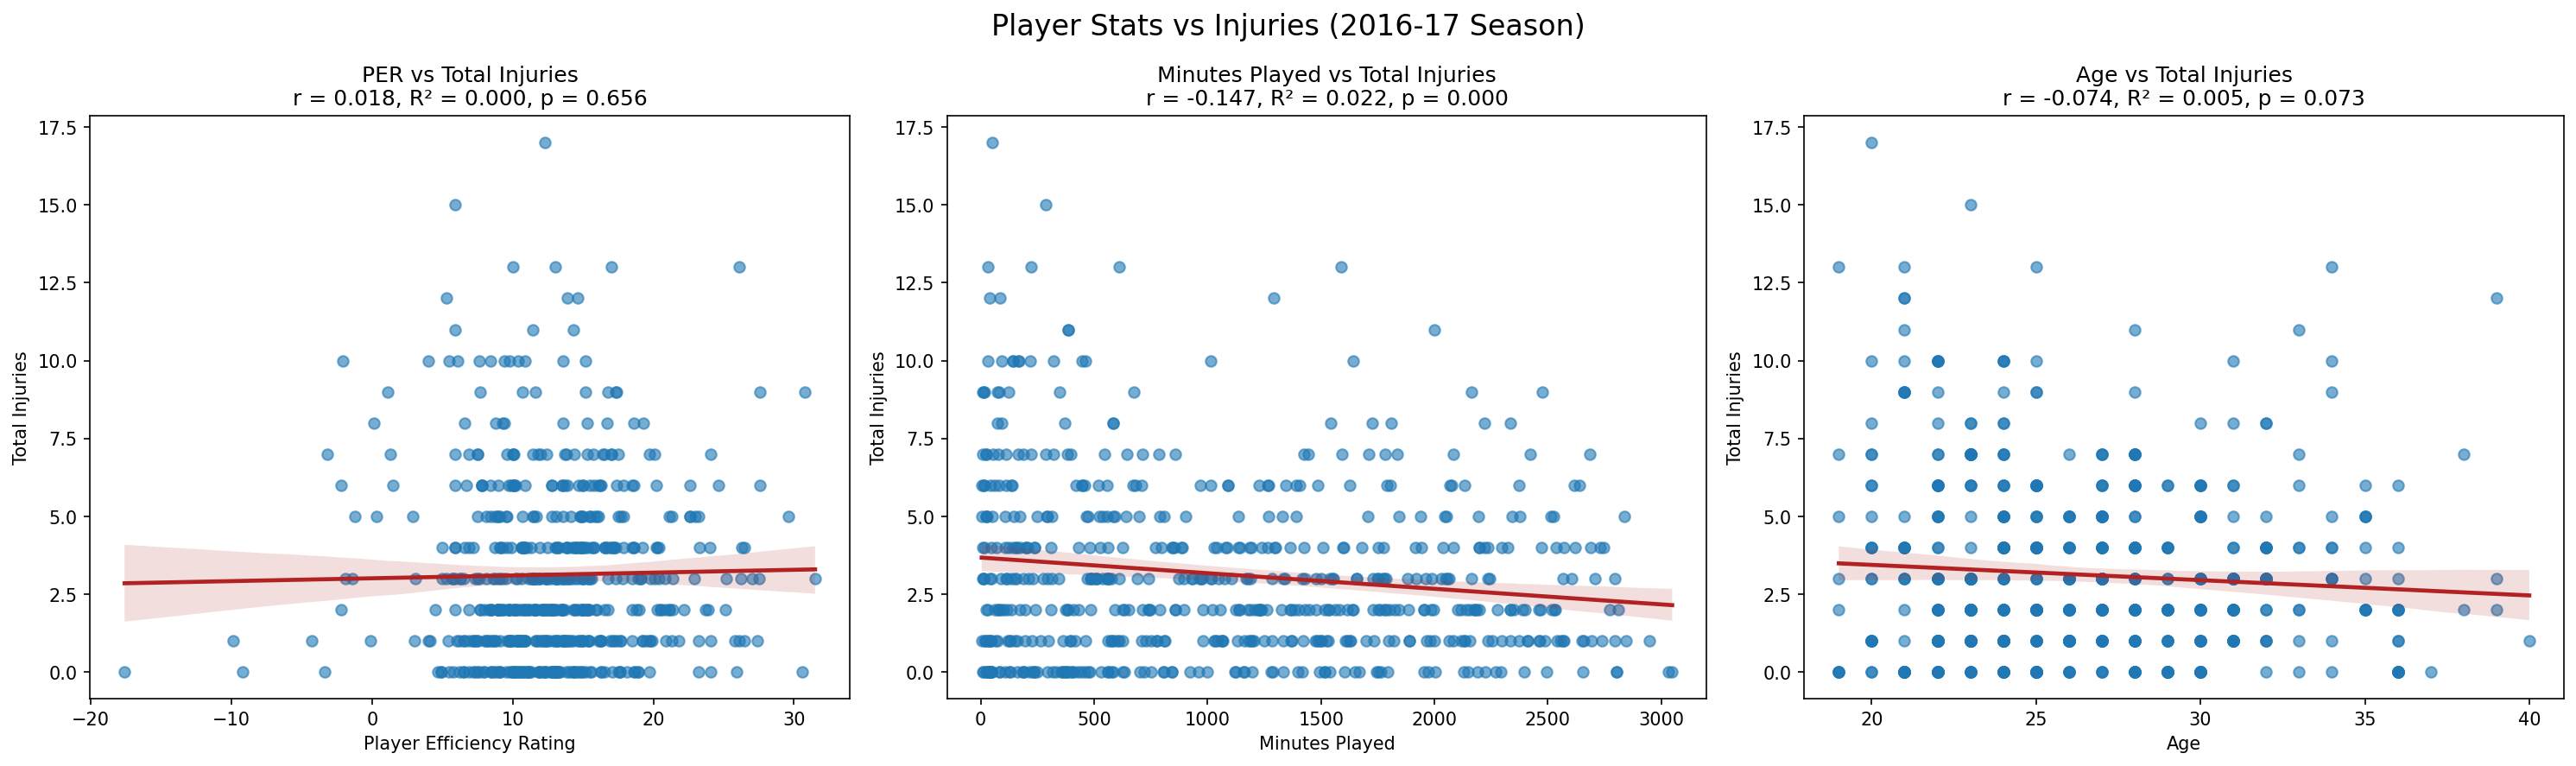

In [2]:
from IPython.display import Image
Image('results/injury_04_regression.png')

* PER vs Total Injuries: r = 0.018, R² = 0.000, p = 0.656: no significant relationship
* Minutes Played vs Total Injuries: r = -0.147, R² = 0.022, p = 0.000: small but significant negative relationship
* Age vs Total Injuries: r = -0.074, R² = 0.005, p = 0.073: no significant relationship

The results largely contradict our hypothesis. PER and age show no significant relationship with injury frequency. Minutes played does not have enough significance with a p < 0.001, but the relationship is actually negative where players with more minutes had fewer reported injuries, which is the opposite of what we predicted. This likely reflects that players who stay healthy are the ones who accumulate high minutes, while injured players miss games and therefore had fewer total minutes. Age shows a slight negative trend as well but does not reach significance. Overall, none of the three predictors meaningfully explain injury frequency, and the small R² values (0.000–0.022) confirm that player performance statistics are poor predictors of injuries within a single season.

### Social Media Engagement Results

<u>To see the code responsible for EDA analyses see 02-EDACheckpoint.ipynb</u>

For the social power dataset we first made a log transformation to both retweets and likes and then ran a for each loop with the code below (mpg is just for the example). 

fg (retweets): r = 0.425, p = 0.000
fg (likes): r = 0.400, p = 0.000


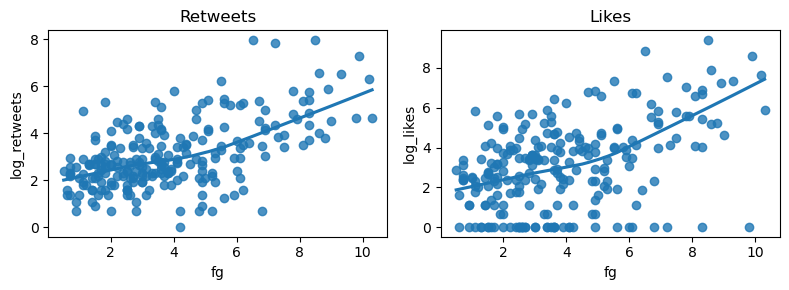

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

r_rt, p_rt = pearsonr(df_social['mpg'], df_social['log_retweets'])
print(f"{'fg'} (retweets): r = {r_rt:.3f}, p = {p_rt:.3f}") 
sns.regplot(y='log_retweets', x='fg', data=df_social,lowess=True, ax=axes[0])
axes[0].set_title("Retweets")
    
r_lk, p_lk = pearsonr(df_social['mpg'], df_social['log_likes'])
print(f"{'fg'} (likes): r = {r_lk:.3f}, p = {p_lk:.3f}")
sns.regplot(y='log_likes', x='fg', data=df_social, lowess=True, ax=axes[1])
axes[1].set_title("Likes")
    
plt.tight_layout()
plt.show()

We looked at the variables with correlation coefficients further from 0 and with p values less than 0.05. We found that the most predictive variables for high retweets and likes were <u>**points**</u>(field goals and free throws both total and attempted but not percentage completed), <u>**turnovers**</u>, and <u>**PIE**</u>(player impact estimate). 

For the two categorical variables, position and team, we first ran box plots. At first sight we noticed that that most players had similar retweets and likes no matter their position but there was a difference between teams. We did ANOVA tests and as we expected for positons all their p values were significantly greater than 0.05, but for teams a few did have p values less than 0.05. We found that being in the following teams can indicate high social media engagement: 
- Chicago Bulls
- Cleveland Cavliers
- Dallas Mavericks
- Golden State Warriors
- Houston Rockets
- Los Angeles Clippers
- Los Angeles Lakers
- Minnesota Timberwolves
- New York Knicks
- OKC Thunders
- San Antonio Spurs

### Performance Metrics vs Career Game Wins

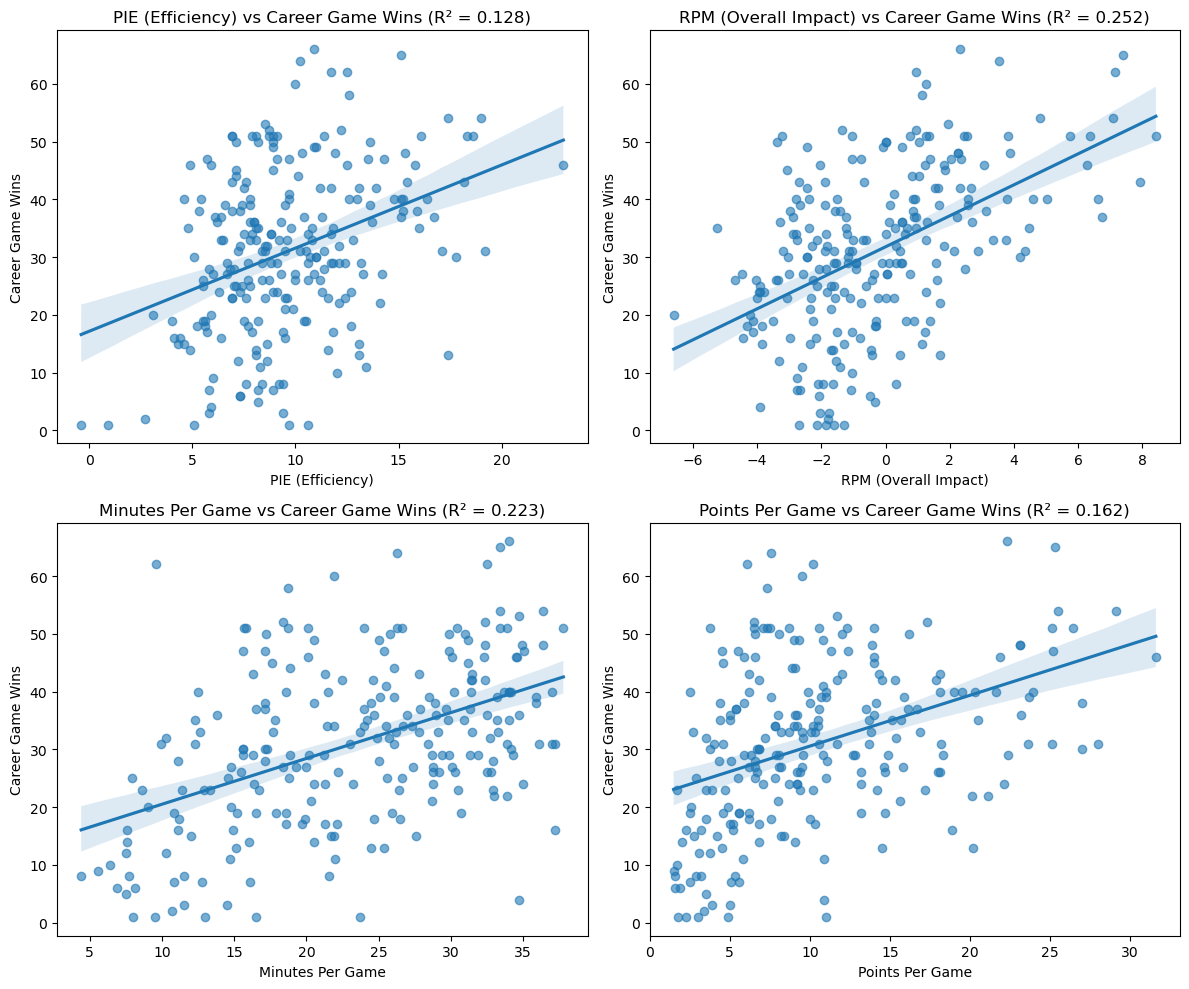

In [8]:
metrics = [
    ('pie', 'PIE (Efficiency)'),
    ('rpm', 'RPM (Overall Impact)'),
    ('mpg', 'Minutes Per Game'),
    ('points', 'Points Per Game')
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (col, label) in zip(axes, metrics):

    # regression using scipy.stats
    slope, intercept, r_value, p_value, std_err = stats.linregress(df_social[col], df_social['wins'])
    r2 = r_value**2

    # scatter + regression line
    sns.regplot(x=col, y='wins', data=df_social, ax=ax, scatter_kws={'alpha':0.6})

    ax.set_title(f'{label} vs Career Game Wins (R² = {r2:.3f})')
    ax.set_xlabel(label)
    ax.set_ylabel('Career Game Wins')

plt.tight_layout()
plt.show()

The scatter plots with regression lines shows the relationship between performance metrics and career game wins. Each plot compares PIE, RPM, minutes per game, and points per game with total career wins and includes an R² value to show the strength of the relationship. The results show positive trends, with PIE and RPM having stronger relationships with career wins. Minutes per game also shows a positive relationship, while points per game has a weaker correlation, suggesting scoring alone is a less strong predictor of career wins.

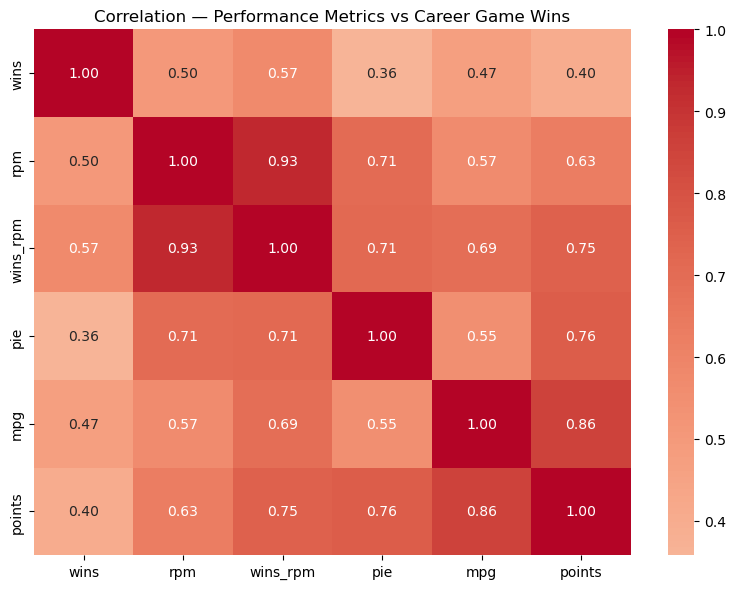

In [9]:
hypothesis_cols = ['wins', 'rpm', 'wins_rpm', 'pie', 'mpg', 'points']

plt.figure(figsize=(8, 6))
corr = df_social[hypothesis_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation — Performance Metrics vs Career Game Wins')
plt.tight_layout()
plt.show()

This identifies a developing positive correlation between advanced impact metrics and career game wins. Players with greater efficiency (PIE) and overall impact (RPM, wins_rpm) metrics ratios, tend to capture more career wins, supporing the hypothesis that stronger contributions directly correlate with team success. Players with greater playing opportunities, captured by minutes per game (MPG), equally possess more career wins, indicative that more consistent court time allows players to exert impact influence over extended periods. Scoring output, captured by points per game, demonstrates a moderate positive correlation with wins, with less significant impact than advanced impact metrics, scoring suggests that raw scoring is a less potent predictor of team success. The correlation heatmap confirms previous observations of variables most correlated with career game wins, namely, RPM, wins_rpm, PIE, and MPG. Altogether, results support the hypothesis that efficiency, overall impact, and playing opportunity are significant drivers of career wins, emphasizing total contribution without scoring.

## XGBoost validation

To better understand the features that contribute to player success the most, we extended the analysis by using a machine learning approach. Since previous approaches such as correlation or regression being used to identify relationships between variables may not completely capture the relationships between statistics, we implemented an XGBoost regression model. This was due to its ability to rank feature importance effectively and model nonlinear relationships which we can use to compare to our other findings

First all we had to bring over our merged datasets in order to train XGBoost under them

In [10]:
# Datasets from earlier to merge them for training data

injury_r['Date'] = pd.to_datetime(injury_r['Date'])
injury_a['Date'] = pd.to_datetime(injury_a['Date'])

# Count total injuries per player
injury_counts = injury_r.groupby('Relinquished').size().reset_index(name='total_injuries')

# Calculate recovery days
merged_injury = pd.merge(
    injury_r[['Date','Relinquished','Notes']].rename(columns={'Date':'injury_date','Relinquished':'player'}),
    injury_a[['Date','Acquired']].rename(columns={'Date':'clear_date','Acquired':'player'}),
    on='player'
)
merged_injury = merged_injury[merged_injury['clear_date'] > merged_injury['injury_date']]
merged_injury = merged_injury.sort_values('clear_date').groupby(['player','injury_date']).first().reset_index()
merged_injury['days_missed'] = (merged_injury['clear_date'] - merged_injury['injury_date']).dt.days

# Total days missed per player
days_missed = merged_injury.groupby('player')['days_missed'].sum().reset_index(name='total_days_missed')

# Combine into one summary df
injury_summary = pd.merge(injury_counts, days_missed,
                           left_on='Relinquished', right_on='player', how='outer')
injury_summary = injury_summary.drop(columns='player').rename(columns={'Relinquished':'player'})

injury_summary


,player,total_injuries,total_days_missed
0,(James) Mike Scott,2,38.0
1,(William) Tony Parker,13,280.0
2,A.J. Hammons,10,59.0
3,Aaron Brooks,3,8.0
4,Aaron Gordon,4,22.0
...,...,...,...
563,Zach Collins,1,3.0
564,Zach LaVine,3,4.0
565,Zach Randolph,3,7.0
566,Zaur Pachulia / Zaza Pachulia,5,58.0


In [11]:
import unicodedata

df_stats_injuries = df_stats.copy()
df_social_injuries = df_social.copy()
df_injury_summary = injury_summary.copy()

def remove_accents(name):
    return ''.join(
        c for c in unicodedata.normalize('NFD', name)
        if unicodedata.category(c) != 'Mn'
    )

# Apply to both datasets
df_stats_injuries['player'] = df_stats_injuries['player'].apply(remove_accents)
df_injury_summary['player'] = df_injury_summary['player'].apply(remove_accents)

df_injury_summary['player'] = df_injury_summary['player'].str.replace(r'\(.*?\)\s*', '', regex=True).str.strip()
df_injury_summary['player'] = df_injury_summary['player'].apply(
    lambda x: x.split('/')[-1].strip() if '/' in x else x
)
df_injury_summary['player'] = df_injury_summary['player'].str.replace('.', '', regex=False)

df_stats_injuries['player'] = df_stats_injuries['player'].str.replace('.', '', regex=False)

# Generalize Players
df_stats_injuries['player'] = df_stats_injuries['player'].str.lower().str.strip()
df_social_injuries['player'] = df_social_injuries['player'].str.lower().str.strip()
df_injury_summary['player'] = df_injury_summary['player'].str.lower().str.strip()


In [12]:
# For players with multiple rows, keep the 'xTM' (multi-team totals) row
# For players with only one team, keep that row as-is
def keep_totals(group):
    multi_team = group[group['team'].str.contains('TM', na=False)]
    return multi_team if not multi_team.empty else group

# Function is to remove duplicates as the table repeats the same player as they played for multiple teams throughout the season
df_stats_injuries = df_stats_injuries.groupby(['player', 'season'], group_keys=False).apply(keep_totals)

In [13]:
# Merge the 3 datasets together using player column and left merging to allow more players to appear
df_merged = (
    df_stats_injuries
    .merge(df_social_injuries, on='player', how='left')
    .merge(df_injury_summary, on='player', how='left')
)

# Replace any empty areas with 0
df_merged['total_injuries'] = df_merged['total_injuries'].fillna(0)
df_merged['total_days_missed'] = df_merged['total_days_missed'].fillna(0)

# drop any players that don't have wins listed to allow wins to be the target variable
df_merged = df_merged.dropna(subset=['wins'])

In [14]:
# Drop the target column
X = df_merged.drop(columns=["wins"])

# Drop non-useful categorical/text columns for XGBoost to read properly
X = X.drop(columns=[
    "lg", "player", "player_id", "team_x", "team_y", "pos", "position"
], errors="ignore")

# Keep only numeric data (extra safety)
X = X.select_dtypes(include=["int64", "float64", "bool"])

# Target column/measurement
y = df_merged["wins"]

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [16]:
# Install XGBoost and Implement parameters
!pip install xgboost
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42
)

model.fit(X_train, y_train)

Defaulting to user installation because normal site-packages is not writeable


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

The XGBoost model was configured with the standard hyperparameters in order to maintain balance for the model's performance and interpretability
- 100 estimators was to provide a sufficient learning capacity without overfitting
- the maximum tree depth being set to 4 was to limit the complexity of the model and allow generalization
- The learning rate of 0.1 was chosen as it reduces the risk of overfitting
- The random state ensures the reproducibility of results

In [20]:
from sklearn.metrics import r2_score, mean_squared_error

y_pred = model.predict(X_test)

print("R^2:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

R^2: 0.7798213065472612
MSE: 50.862773289620584


According to the XGBoost model, it is able to explain around 78% of the variation in wins which is strong for real-world data. This is basically saying that the model was able to capture the relationship of wins and stats pretty well.
The MSE or Mean Squared Error is meant to understand how far off the data is where in this case it was off from around 7 wins.

In [18]:
import pandas as pd

# Identify the most important features to predict wins (higher number means higher importance)
importance = model.feature_importances_

# Creates a DataFrame of the rankings of importances for each feature
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

feature_importance.head(10)

,Feature,Importance
2,g,0.179946
20,ws_48,0.124632
18,dws,0.069834
25,age_y,0.048452
35,efg_pct,0.040365
55,pace,0.039112
33,2pa,0.037526
52,rpm,0.031826
37,fta,0.031586
45,tov,0.024648


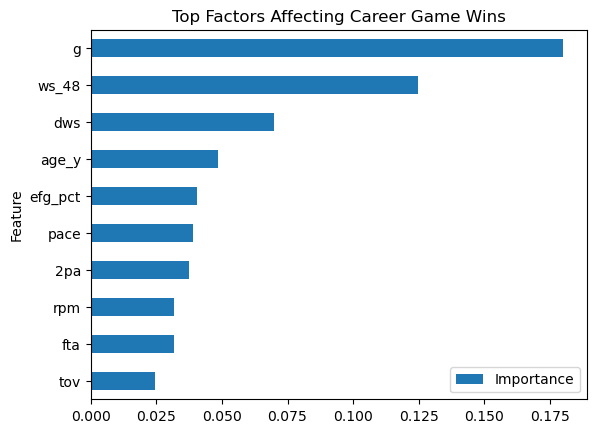

In [19]:
import matplotlib.pyplot as plt

# Creates a bar graph to compare rates of importance among the features
feature_importance.head(10).plot(
    kind="barh", x="Feature", y="Importance"
)

plt.gca().invert_yaxis()
plt.title("Top Factors Affecting Career Game Wins")
plt.show()

   As a result it appears that g (games played), ws_48 (win shares per 48 minutes), age_y (age), and dws (Defensive Win Shares) are rated to be the top 4 most important features. Games played makes sense as the more the player plays, the increased opportunity it is for the team to win with them on the court. WS_48 and dws were the next most important which makes sense as it's a measure of the players efficiency performance and defensive rating, as it's also a saying in basketball to which "defense wins games." Age makes sense as a player's age is able to determine their performance as there is a prime-age for players that allows peak performance and maximum athleticism.
\
\
       This compares to our findings in which RPM, Wins_RPM, PIE, and MPG were found to have the highest correlation with wins which mostly agrees with the data that XGBoost found, however the rankings are a little bit different. MPG and PIE are not found in the top 10 however the other 2 are. This can be due to the fact that XGBoost is able to see all the features at once allowing it to spot things that humans can't easily spot manually. Additionally, our analysis could've been affected by outliers and the fact that we can only look at individual features at a time. The data for the model also had to remove some players due to them lacking wins which could've also affected the data and affected the rates of importance
\
\
    Ultimately this data mostly supports our hypothesis in which success is best found through their player efficiency and win shares as the model puts them at high importance for predicting wins and success.

## Ethics

### A. Data Collection
 - [X] **A.1 Informed consent**: If there are human subjects, have they given informed consent, where subjects affirmatively opt-in and have a clear understanding of the data uses to which they consent?

This project uses publicly available NBA statistics, injury reports, and social media engagement data. Informed consent is not applicable because no private or personally identifiable information is collected.

 - [X] **A.2 Collection bias**: Have we considered sources of bias that could be introduced during data collection and survey design and taken steps to mitigate those?

Biases may exist in the historical record (e.g., more data on popular players, larger market teams, or players active in recent seasons with Twitter). We acknowledge these biases and will consider them when interpreting predictions.

 - [X] **A.3 Limit PII exposure**: Have we considered ways to minimize exposure of personally identifiable information (PII) for example through anonymization or not collecting information that isn't relevant for analysis?

All data used are publicly available and consist solely of player statistics, injury records, and social media engagements. No personally identifiable information is collected, ensuring that the analysis only relies on relevant, non-sensitive data. 

 - [ ] **A.4 Downstream bias mitigation**: Have we considered ways to enable testing downstream results for biased outcomes (e.g., collecting data on protected group status like race or gender)?

### B. Data Storage
 - [X] **B.1 Data security**: Do we have a plan to protect and secure data (e.g., encryption at rest and in transit, access controls on internal users and third parties, access logs, and up-to-date software)?

All data are publicly available and can be accessed by anyone. Because the dataset contains only non-sensitive, public information, security and privacy risks are minimal.

 - [ ] **B.2 Right to be forgotten**: Do we have a mechanism through which an individual can request their personal information be removed?

 - [X] **B.3 Data retention plan**: Is there a schedule or plan to delete the data after it is no longer needed?

The data will be retained for future academic reference and reproducibility. Since it consists solely of publicly available NBA player statistics, injury histories, and social media engagements, long-term storage does not pose privacy or ethical risks.

### C. Analysis
 - [X] **C.1 Missing perspectives**: Have we sought to address blindspots in the analysis through engagement with relevant stakeholders (e.g., checking assumptions and discussing implications with affected communities and subject matter experts)?

The analysis considers that historical statistics, injury records, and social media engagement may not capture all factors influencing career wins, injuries, or popularity. These limitations are acknowledged when interpreting the results and drawing conclusions.
       
 - [X] **C.2 Dataset bias**: Have we examined the data for possible sources of bias and taken steps to mitigate or address these biases (e.g., stereotype perpetuation, confirmation bias, imbalanced classes, or omitted confounding variables)?

We examine potential biases related to player position, minutes played, injury history, era, team size, and data availability. These factors are accounted for in the analysis to minimize confounding and ensure that predictions of career wins, injuries, and social media engagement are as fair and accurate as possible.

 - [X] **C.3 Honest representation**: Are our visualizations, summary statistics, and reports designed to honestly represent the underlying data?

All metrics, visualizations, and summaries are presented transparently to accurately reflect relationships between player statistics, injuries, and social media engagement, ensuring an honest depiction of model performance.

 - [X] **C.4 Privacy in analysis**: Have we ensured that data with PII are not used or displayed unless necessary for the analysis?

No private or sensitive data are used or displayed at any stage of the analysis.

 - [X] **C.5 Auditability**: Is the process of generating the analysis well documented and reproducible if we discover issues in the future?

Every step of data preprocessing, the rationale behind modeling decisions, and the methods used for evaluating the model are fully documented to ensure that the analysis can be reproduced accurately.

### D. Modeling
 - [X] **D.1 Proxy discrimination**: Have we ensured that the model does not rely on variables or proxies for variables that are unfairly discriminatory?

The XGBoost model uses only player statistics, injury histories, and social media engagements. No features serve as proxies for protected attributes, ensuring predictions are based solely on relevant performance and engagement data.

 - [X] **D.2 Fairness across groups**: Have we tested model results for fairness with respect to different affected groups (e.g., tested for disparate error rates)?

Model performance is evaluated across player roles, positions, eras, and team types to identify any systematic differences in prediction accuracy.

 - [X] **D.3 Metric selection**: Have we considered the effects of optimizing for our defined metrics and considered additional metrics?

We use multiple evaluation metrics, including error in predicting career wins, injury counts, and social media engagement, to avoid over-optimizing for a single outcome.

 - [X] **D.4 Explainability**: Can we explain in understandable terms a decision the model made in cases where a justification is needed?

Feature importance scores from the XGBoost model are used to explain how historical stats, injuries, and social media engagement influence predictions.

 - [X] **D.5 Communicate limitations**: Have we communicated the shortcomings, limitations, and biases of the model to relevant stakeholders in ways that can be generally understood?

We clearly acknowledge that predictions are probabilistic, subject to uncertainty, and may be influenced by missing or incomplete historical data. Limitations and potential biases are communicated in all analyses.

### E. Deployment
 - [ ] **E.1 Monitoring and evaluation**: Do we have a clear plan to monitor the model and its impacts after it is deployed (e.g., performance monitoring, regular audit of sample predictions, human review of high-stakes decisions, reviewing downstream impacts of errors or low-confidence decisions, testing for concept drift)?
    
 - [ ] **E.2 Redress**: Have we discussed with our organization a plan for response if users are harmed by the results (e.g., how does the data science team evaluate these cases and update analysis and models to prevent future harm)?
       
 - [ ] **E.3 Roll back**: Is there a way to turn off or roll back the model in production if necessary?

 - [X] **E.4 Unintended use**: Have we taken steps to identify and prevent unintended uses and abuse of the model and do we have a plan to monitor these once the model is deployed?

This study evaluates whether historical NBA player statistics, injury histories, and social media engagements can predict career wins, injury counts, and popularity. The analysis is conducted strictly for academic and methodological purposes, providing a framework to assess predictive modeling techniques. It is not intended for guiding personnel decisions, betting, or any financial or commercial applications, and all findings are framed in a research-focused context.

## Discussion and Conclusion

Our results were the following:
- Players with high impact and playtime tend to have more career wins.
- Player performance statistics are poor predictors of injuries within a single season.
- Players with high scoring output and impact have better social media engagement.

For injuries, we found a slightly negative correlation between minutes per game and injured players. This may seems contradictory at first because we would expect players who have more play time to be more prone to injury. The most likely reason why this correlation appeared is because when players get injured they are unable to play, decreasing their minutes per game stat. So, the problem with our data is that it is including the players overall minutes per game, not only their minutes per game while healthy which would be best.

Our overall results show that wins, injuries and social media engagement may have some difference in predictive variables. We learned that injuries can be unpredictable and we could not find a good variable which was indicative of injuries. We still believe that high playtime could predict injuries but we would need another dataset or modify our own so that minutes per game is not affected by the lack of playtime players are faced with when recovering of an injury. We learned that high career wins and high social media engagement share some predictive variables. Players with high impact are likely to have both high career wins and high social media engagement. The only difference is that points have a greater correlation to social media engagement than to wins, and vice versa for minutes per game.

Looking back at our background section, we were initially limited to the 2016-17 season because the only dataset found with the social media engagement was from that season. Despite the limitation, we were still able to implement XGBoost and used it as a validation tool to compare to our personal findings which allowed us to go further than correlation and find feature importance across all variables at the same time. Despite correlation still being our primary tool, XGBoost strengthened the final analysis over wins by confirming the most important predictors that aligned with our personal findings which mainly fell along the lines of player efficiency and win shares. However, having more seasons of social media data would help extend and improve the same modeling approach.

Every sport evolves and basketball is not an exception to this. Using data from the 2016-17 season is limiting because its been almost a decade and the sport has certainly changed. To make a quick example, in our social media results we found that being part of certain teams can be predictive of high social media engagement and it is very likely that those teams have changed nowadays because as the sport adapts teams do to and some do better than others. As the game evolves predictive variables for wins may change, maybe impact could lose some correlation and efficiency gain more, the winning factors may change. Social media users and viewers of the sport also change, every day it is more common for people to watch stats or highlights so predictive variables for social media engagement may change.

If we were to continue our work, we would need to first find a more recent dataset with more seasons for social media engagement. The datasets used to statistics and injuries contain decades of information, so we would not need more than that. Having more data we could create models to find if our results were correct and from there we could expand to find specific numbers instead of just predictive variables. We could try to find a way to find the specific amount of career wins a player would have if given their average PIE, RPM, and minutes per game. There are many different paths we could take from here but for social media engagement we are currently limited by the dataset.